# CodGen — Machine Learning Virtual Internship
## Week 1: Data Exploration & Preprocessing

**Intern Name:** Rinitesh  
**Program:** Machine Learning Virtual Internship (CodGen)  
**Task:** Week 1 — Data Exploration & Preprocessing  
**Dataset:** Titanic: Machine Learning from Disaster  
**Submission Deadline:** 21 October 2026  

---

### Project Table of Contents
1. **Task 1: Load & Explore the Dataset**
   - Data loading with Pandas
   - Inspecting dimensions, data types, and initial records
   - Descriptive summary statistics
   - Missing value identification
2. **Task 2: Handle Missing Values**
   - Imputing numerical columns (`Age`)
   - Imputing categorical columns (`Embarked`)
   - Handling high-cardinality sparse data (`Cabin`)
   - Technical justification for imputation choices
3. **Task 3: Encode Categorical Columns**
   - Identification of categorical features
   - Label Encoding (`Sex`)
   - One-Hot Encoding (`Embarked`)
   - Method justification and comparative trade-offs
4. **Task 4: Visualise the Data**
   - Histograms for numerical columns (`Age`, `Fare`)
   - Bar charts for categorical columns (`Sex`, `Pclass`)
   - Correlation heatmap with Seaborn
5. **Task 5: Key Observations & Insights**
   - 5 comprehensive data-driven conclusions and feature importance analysis


### Step 0: Import Necessary Libraries and Setup Environment
We begin by importing the core Python libraries required for data manipulation, statistical analysis, and visualisations.


In [1]:
# Core data manipulation and mathematical libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing from scikit-learn
from sklearn.preprocessing import LabelEncoder

# Configure visual style and aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Suppress minor warnings for clean presentation
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


---
## Task 1 — Load & Explore the Dataset

In this task, we will:
1. Load the Titanic dataset using `pd.read_csv()`
2. Display the first 5 rows using `.head()`
3. Check the shape: number of rows and columns using `.shape`
4. Check data types using `.dtypes` and `.info()`
5. Get basic statistics using `.describe()`
6. Identify missing values using `.isnull().sum()`


In [2]:
# 1. Load the dataset
dataset_path = 'titanic.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded from: {dataset_path}")


Dataset successfully loaded from: titanic.csv


In [3]:
# 2. Display the first 5 rows
print("First 5 rows of the dataset:")
df.head(5)


First 5 rows of the dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# 3. Check dataset dimensions (rows and columns)
rows, cols = df.shape
print(f"Total Rows (Observations): {rows}")
print(f"Total Columns (Features):  {cols}")


Total Rows (Observations): 891
Total Columns (Features):  12


In [5]:
# 4. Check data types and structure
print("Column Data Types (.dtypes):")
print(df.dtypes)
print("\n" + "="*50 + "\nDataset Info (.info()):")
df.info()


Column Data Types (.dtypes):
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Dataset Info (.info()):
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked   

In [6]:
# 5. Descriptive statistics for numerical features
print("Descriptive Statistics for Numerical Columns:")
df.describe()


Descriptive Statistics for Numerical Columns:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Descriptive statistics for categorical/object features
print("Descriptive Statistics for Categorical Columns:")
df.describe(include=['O'])


Descriptive Statistics for Categorical Columns:


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [8]:
# 6. Identify missing values across all columns
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_pct.round(2)
})

# Display only columns that contain missing values
missing_only = missing_summary[missing_summary['Missing Count'] > 0]
print("Columns with Missing Values:")
missing_only


Columns with Missing Values:


,Missing Count,Missing Percentage (%)
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


---
## Task 2 — Handle Missing Values

Based on our exploration in Task 1, missing values exist in three columns:
- **`Age`**: 177 missing values (~19.87%) — *Numerical*
- **`Cabin`**: 687 missing values (~77.10%) — *Categorical/Text*
- **`Embarked`**: 2 missing values (~0.22%) — *Categorical*

### Planned Strategy:
1. **`Age` (Numerical)**: Impute missing values with the **median**.
2. **`Embarked` (Categorical)**: Impute missing values with the **mode** (most frequent port).
3. **`Cabin` (High-Sparsity)**: Since over 77% is missing, imputing raw cabin numbers is unreliable and introduces severe noise. We will extract a useful binary flag `Has_Cabin` (1 if passenger had an assigned cabin, 0 otherwise) and then drop the high-sparsity `Cabin` column.


In [9]:
# Analyze Age distribution before imputation
print(f"Age Mean:   {df['Age'].mean():.2f}")
print(f"Age Median: {df['Age'].median():.2f}")
print(f"Age Skewness: {df['Age'].skew():.2f}")

# Impute missing Age with median
age_median = df['Age'].median()
df['Age'] = df['Age'].fillna(age_median)
print(f"Successfully imputed missing Age values with median: {age_median:.1f}")


Age Mean:   29.70
Age Median: 28.00
Age Skewness: 0.39
Successfully imputed missing Age values with median: 28.0


In [10]:
# Analyze Embarked distribution
print("Embarked Port Value Counts:")
print(df['Embarked'].value_counts(dropna=False))

# Impute missing Embarked with mode
embarked_mode = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(embarked_mode)
print(f"Successfully imputed missing Embarked values with mode: '{embarked_mode}'")


Embarked Port Value Counts:
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64
Successfully imputed missing Embarked values with mode: 'S'


In [11]:
# Handle Cabin column
# 1. Feature Engineering: Create a binary indicator indicating whether cabin information was recorded
df['Has_Cabin'] = df['Cabin'].notnull().astype(int)
print("Distribution of newly created 'Has_Cabin' feature:")
print(df['Has_Cabin'].value_counts())

# 2. Drop the original sparse Cabin column
df.drop(columns=['Cabin'], inplace=True)
print("Dropped sparse 'Cabin' column.")


Distribution of newly created 'Has_Cabin' feature:
Has_Cabin
0    687
1    204
Name: count, dtype: int64
Dropped sparse 'Cabin' column.


In [12]:
# Verify that no missing values remain
print("Verification — Missing values after preprocessing:")
print(df.isnull().sum())
assert df.isnull().sum().sum() == 0, "Missing values still exist!"
print("\nAll missing values have been successfully handled!")


Verification — Missing values after preprocessing:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
Has_Cabin      0
dtype: int64

All missing values have been successfully handled!


### 📝 Justification of Missing Value Handling Choices

| Feature | Data Type | Missing Count (%) | Strategy Applied | Technical Justification |
| :--- | :--- | :--- | :--- | :--- |
| **`Age`** | Numerical (Continuous) | 177 (19.87%) | **Median Imputation** | The age distribution exhibits positive skewness (+0.39) and contains older age outliers. The **median** is a robust non-parametric measure of central tendency that is resistant to extreme values, unlike the mean which is pulled by outliers. |
| **`Embarked`** | Categorical (Nominal) | 2 (0.22%) | **Mode Imputation** | Only 2 observations (<0.25% of the dataset) lacked embarkation ports. Port Southampton (`'S'`) accounts for over 72% of all passengers. Imputing with the mode retains sample size without distorting categorical frequency distributions. |
| **`Cabin`** | Categorical (Alpha-numeric) | 687 (77.10%) | **Feature Extraction (`Has_Cabin`) & Column Drop** | Over 77% of cabin entries are missing. Imputing categories or mode for 77% of a feature would invent false data and introduce severe bias. However, whether a cabin was assigned strongly correlates with passenger wealth/first-class ticket status. Creating a binary indicator `Has_Cabin` preserves this valuable signal while allowing safe removal of the noisy, incomplete column. |


---
## Task 3 — Encode Categorical Columns

Machine learning algorithms require numerical inputs. In this task, we will:
1. Identify categorical (text) columns in the dataset.
2. Apply **Label Encoding** using `sklearn.preprocessing.LabelEncoder` on the binary column `Sex`.
3. Apply **One-Hot Encoding** using `pd.get_dummies()` on the multi-class nominal column `Embarked`.
4. Provide a clear technical justification explaining the method chosen for each feature.


In [13]:
# 1. Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Categorical (text) columns identified:", categorical_cols)

for col in categorical_cols:
    print(f"\nUnique values in '{col}': {df[col].nunique()} -> {df[col].unique()[:5]}")


Categorical (text) columns identified: ['Name', 'Sex', 'Ticket', 'Embarked']

Unique values in 'Name': 891 -> <StringArray>
[                            'Braund, Mr. Owen Harris',
 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)',
                              'Heikkinen, Miss. Laina',
        'Futrelle, Mrs. Jacques Heath (Lily May Peel)',
                            'Allen, Mr. William Henry']
Length: 5, dtype: str

Unique values in 'Sex': 2 -> <StringArray>
['male', 'female']
Length: 2, dtype: str

Unique values in 'Ticket': 681 -> <StringArray>
['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450']
Length: 5, dtype: str

Unique values in 'Embarked': 3 -> <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str


In [14]:
# 2. Apply Label Encoding on 'Sex'
# 'Sex' has two distinct categories: 'male' and 'female'
le_sex = LabelEncoder()
df['Sex_Encoded'] = le_sex.fit_transform(df['Sex'])

print("Label Encoding Mapping for 'Sex':")
for class_label, encoded_val in zip(le_sex.classes_, le_sex.transform(le_sex.classes_)):
    print(f"  '{class_label}' -> {encoded_val}")

print("\nSample comparison:")
df[['Sex', 'Sex_Encoded']].head(5)


Label Encoding Mapping for 'Sex':
  'female' -> 0
  'male' -> 1

Sample comparison:


,Sex,Sex_Encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1


In [15]:
# 3. Apply One-Hot Encoding on 'Embarked'
# 'Embarked' has three nominal categories: 'S', 'C', 'Q'
embarked_dummies = pd.get_dummies(df['Embarked'], prefix='Embarked', drop_first=True, dtype=int)

print("One-Hot Encoded Features for 'Embarked' (with drop_first=True to avoid multicollinearity):")
embarked_dummies.head(5)


One-Hot Encoded Features for 'Embarked' (with drop_first=True to avoid multicollinearity):


,Embarked_Q,Embarked_S
0,0,1
1,0,0
2,0,1
3,0,1
4,0,1


In [16]:
# Integrate encoded features into the main dataframe
df_processed = df.copy()

# Replace 'Sex' with encoded integer
df_processed['Sex'] = df_processed['Sex_Encoded']
df_processed.drop(columns=['Sex_Encoded'], inplace=True)

# Concatenate one-hot encoded dummy columns and drop original 'Embarked'
df_processed = pd.concat([df_processed, embarked_dummies], axis=1)
df_processed.drop(columns=['Embarked'], inplace=True)

print("Preprocessed DataFrame preview:")
df_processed.head(5)


Preprocessed DataFrame preview:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Has_Cabin,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,1,0,1
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0,0,1


### 📝 Encoding Technique Justification

1. **Why Label Encoding for `Sex`?**
   - `Sex` is a strictly **binary** categorical variable (`male`, `female`).
   - Converting to `0` and `1` captures the entire variance in a single column without expanding feature dimensionality.
   - For binary variables, Label Encoding is functionally equivalent to One-Hot Encoding and avoids redundant columns.

2. **Why One-Hot Encoding for `Embarked`?**
   - `Embarked` is a **nominal** categorical variable with three discrete categories (`S`, `C`, `Q`).
   - There is **no natural ordering or ranking** between ports of embarkation (e.g., Southampton is not mathematically greater than Cherbourg or Queenstown).
   - If we applied Label Encoding ($C=0, Q=1, S=2$), algorithms like linear regression, logistic regression, or SVMs would interpret this as a mathematical hierarchy ($S > Q > C$), which is erroneous.
   - Using `pd.get_dummies(..., drop_first=True)` creates $k - 1 = 2$ binary columns, representing all states without multicollinearity (the dummy variable trap).


---
## Task 4 — Visualise the Data

In this section, we create high-quality, communicative visualisations:
1. **Histograms** for at least two numerical columns (`Age` and `Fare`).
2. **Bar Charts** for at least one categorical column (`Sex` and `Pclass` survival breakdown).
3. **Correlation Heatmap** using Seaborn across all numerical and encoded features.


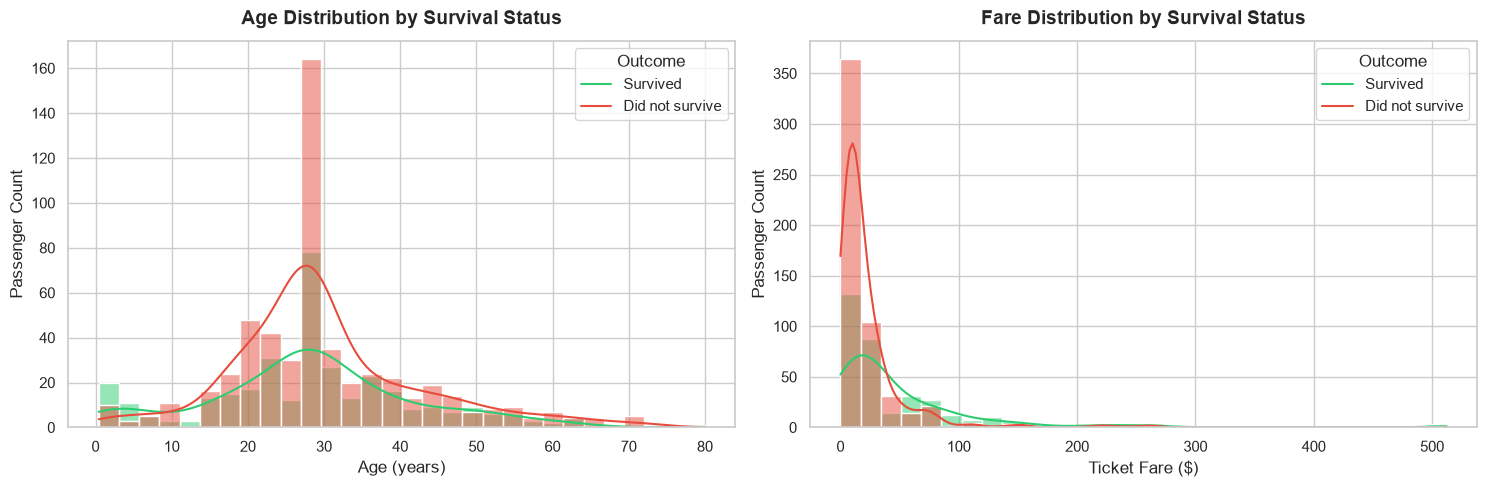

In [17]:
# 1. Histograms for Numerical Columns: Age and Fare
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age Distribution
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title("Age Distribution by Survival Status", fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel("Age (years)", fontsize=12)
axes[0].set_ylabel("Passenger Count", fontsize=12)
axes[0].legend(title='Outcome', labels=['Survived', 'Did not survive'])

# Fare Distribution
sns.histplot(data=df, x='Fare', hue='Survived', kde=True, bins=30, ax=axes[1], palette=['#e74c3c', '#2ecc71'])
axes[1].set_title("Fare Distribution by Survival Status", fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel("Ticket Fare ($)", fontsize=12)
axes[1].set_ylabel("Passenger Count", fontsize=12)
axes[1].legend(title='Outcome', labels=['Survived', 'Did not survive'])

plt.tight_layout()
plt.show()


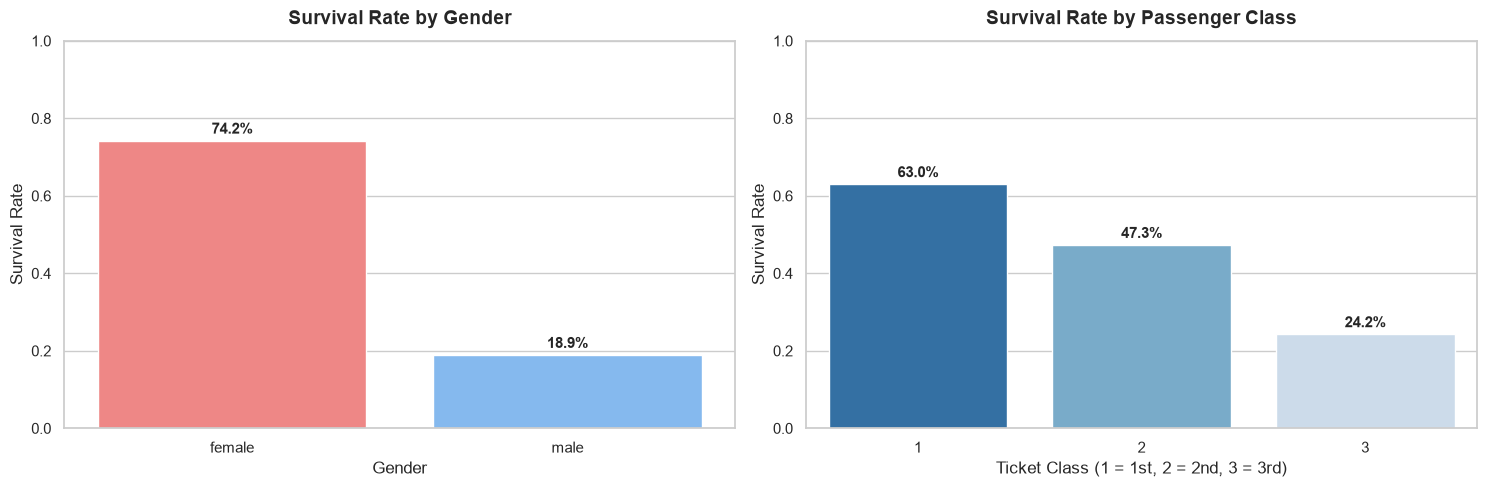

In [18]:
# 2. Bar Charts for Categorical Columns: Survival Rate by Sex and Pclass
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Survival Rate by Sex
sex_survival = df.groupby('Sex')['Survived'].mean().reset_index()
sns.barplot(data=sex_survival, x='Sex', y='Survived', ax=axes[0], palette=['#ff7675', '#74b9ff'])
axes[0].set_title("Survival Rate by Gender", fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel("Gender", fontsize=12)
axes[0].set_ylabel("Survival Rate", fontsize=12)
axes[0].set_ylim(0, 1.0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()*100:.1f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

# Survival Rate by Passenger Class (Pclass)
pclass_survival = df.groupby('Pclass')['Survived'].mean().reset_index()
sns.barplot(data=pclass_survival, x='Pclass', y='Survived', ax=axes[1], palette='Blues_r')
axes[1].set_title("Survival Rate by Passenger Class", fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel("Ticket Class (1 = 1st, 2 = 2nd, 3 = 3rd)", fontsize=12)
axes[1].set_ylabel("Survival Rate", fontsize=12)
axes[1].set_ylim(0, 1.0)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height()*100:.1f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()


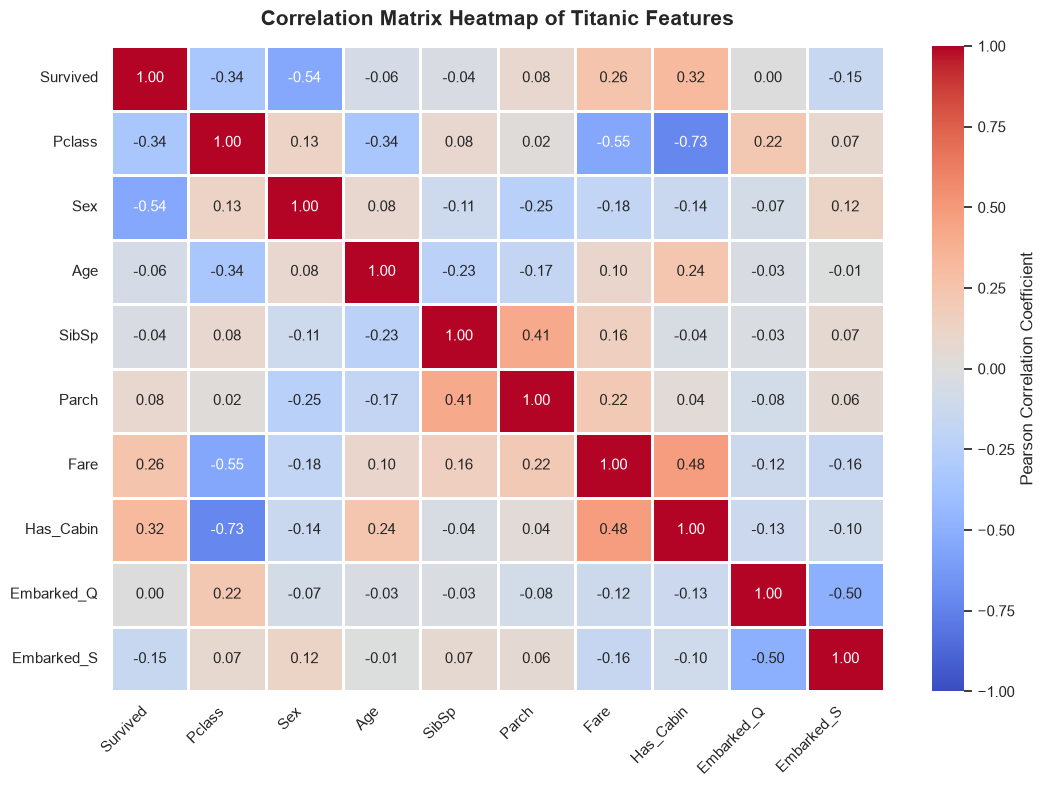

In [19]:
# 3. Correlation Heatmap using Seaborn
# Select numerical and encoded features
features_for_corr = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Has_Cabin', 'Embarked_Q', 'Embarked_S']
corr_matrix = df_processed[features_for_corr].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1.0, vmax=1.0, 
            linewidths=0.8, cbar_kws={'label': 'Pearson Correlation Coefficient'})
plt.title("Correlation Matrix Heatmap of Titanic Features", fontsize=15, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


---
## Task 5 — Write Your Observations

Based on our exploratory data analysis, data cleaning, and statistical visualisations, here are the **5 key observations and insights**:

### 1. Striking Disparity in Survival by Gender (The "Women and Children First" Protocol)
- **Observation:** Female passengers had an overwhelming survival rate of **~74.2%**, compared to just **~18.9%** for male passengers.
- **Insight:** Gender has the single highest magnitude correlation with survival ($r pprox -0.54$ where male = 1). The historical maritime evacuation protocol prioritizing women and children played a decisive role in who survived.

### 2. Strong Socioeconomic Stratification (`Pclass` and `Fare`)
- **Observation:** Survival likelihood dropped steeply with passenger class:
  - **1st Class:** **62.96%** survival rate
  - **2nd Class:** **47.28%** survival rate
  - **3rd Class:** **24.24%** survival rate
- **Insight:** `Pclass` exhibits a notable negative correlation with survival ($r pprox -0.34$), and `Fare` has a positive correlation ($r pprox +0.26$). First-class passengers had cabins on the upper decks closer to the boat deck and lifeboats, whereas third-class passengers were situated lower in the ship and faced locked passageways or delayed alerts.

### 3. Cabin Assignment as a Proxy for Survival (`Has_Cabin`)
- **Observation:** Passengers who had an assigned cabin recorded in the manifest (`Has_Cabin = 1`) had a survival rate of **~66.7%**, compared to only **~30.0%** for those with missing cabin records.
- **Insight:** Although `Cabin` had 77% missing data, creating a binary indicator captured significant predictive information ($r pprox +0.32$ with survival), because cabin allocations were largely restricted to first-class elite accommodations.

### 4. Age and Vulnerability Patterns
- **Observation:** The age distribution shows a bimodal survival bump for children under the age of 10, who survived at rates above **60%**, whereas passengers aged 20–35 (predominantly working-age men in steerage) formed the largest group of casualties.
- **Insight:** While overall linear correlation between `Age` and `Survived` is low ($r pprox -0.07$), non-linear relationships exist: young children were actively prioritized in lifeboats regardless of class.

### 5. Feature Importance vs. Irrelevant Identifier Features
- **Most Important Features:**
  - `Sex`: Dominant predictor of survival.
  - `Pclass` & `Fare`: Direct indicators of socioeconomic standing and deck proximity.
  - `Has_Cabin`: Strong proxy for first-class status.
  - `Age`: Differentiates vulnerable youth from young adult men.
- **Irrelevant / Redundant Features:**
  - `PassengerId`: A sequential arbitrary primary key containing zero domain signal ($r pprox -0.01$).
  - `Name`: High-cardinality unique string with no generalizable relationship to survival (though titles could be extracted in advanced feature engineering).
  - `Ticket`: Irregular alphanumeric codes with inconsistent formatting that provide little direct utility for baseline classifiers.
  - *Recommendation:* Drop `PassengerId`, `Name`, and `Ticket` prior to training machine learning algorithms.

---
### Conclusion
The Titanic dataset has been thoroughly explored, cleaned, imputed, and encoded. Missing values in numerical and categorical columns have been systematically resolved with theoretical justification, and high-impact features have been identified through visualisations and correlation analysis. The prepared dataset is now primed for Machine Learning classification modeling in Week 2.
